In [1]:
import warnings, time, platform
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, joblib, sklearn, xgboost, shap
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
import Data_Prep as dp

SEED = 42
DATA_DIR, MODEL_PATH = Path("Home Credit Data"), Path("final_model.joblib")

# ---- data (same prepared tables and holdout split as the modeling notebook)
train_df = pd.read_csv(DATA_DIR / "prepared" / "application_train_prepared.csv")
feature_cols = [c for c in train_df.columns if c not in ("SK_ID_CURR", "TARGET")]
cat_cols = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(train_df[c])]
for c in cat_cols:
    train_df[c] = train_df[c].astype(object).where(train_df[c].notna(), "Missing")
X, y = train_df[feature_cols], train_df["TARGET"].astype(int)
X_dev, X_hold, y_dev, y_hold = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

# ---- final model (trained in the modeling notebook) and a holdout-fit twin for unbiased metrics
final_pipe = joblib.load(MODEL_PATH)
assert list(final_pipe.named_steps["pre"].feature_names_in_) == feature_cols
t0 = time.time()
val_pipe = clone(final_pipe).fit(X_dev, y_dev)          # same settings, fitted on the 80% development rows
p_hold = val_pipe.predict_proba(X_hold)[:, 1]
HOLDOUT_AUC = roc_auc_score(y_hold, p_hold)

# ---- variant without high-governance fields (for the fairness comparison)
governed = set(dp.HIGH_GOVERNANCE_FEATURES) | {"DAYS_BIRTH", "AGE_BAND", "OCCUPATION_TYPE_MISSING", "CNT_CHILDREN",
    "REG_REGION_NOT_LIVE_REGION", "REG_REGION_NOT_WORK_REGION", "LIVE_REGION_NOT_WORK_REGION",
    "REG_CITY_NOT_LIVE_CITY", "REG_CITY_NOT_WORK_CITY", "LIVE_CITY_NOT_WORK_CITY"}
nogov_cols = [c for c in feature_cols if c not in governed]
def make_pre(cols):
    num = [c for c in cols if c not in cat_cols]; cat = [c for c in cols if c in cat_cols]
    return ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median"))]), num),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False, dtype=np.float32), cat)])
nogov_pipe = Pipeline([("pre", make_pre(nogov_cols)), ("model", clone(final_pipe.named_steps["model"]))]).fit(X_dev[nogov_cols], y_dev)
p_hold_nogov = nogov_pipe.predict_proba(X_hold[nogov_cols])[:, 1]
NOGOV_AUC = roc_auc_score(y_hold, p_hold_nogov)

# ---- cost assumptions (sources in section 4) and profit function
G_BASE, L_BASE = 0.08, 0.70          # profit on a repaid loan, loss given default (shares of the loan amount)
amt = X_hold["AMT_CREDIT"].values; yy = y_hold.values
def outcome(p, t, G=G_BASE, L=L_BASE):
    ok = p < t
    profit = (amt[ok] * (G * (1 - yy[ok]) - L * yy[ok])).sum()
    return {"approval_rate": ok.mean(), "profit": profit, "profit_per_100k": profit / len(p) * 100_000,
            "profit_pct_volume": profit / amt[ok].sum() if ok.any() else np.nan,
            "approved_default_rate": yy[ok].mean() if ok.any() else np.nan}
grid = np.round(np.arange(0.02, 0.401, 0.005), 3)
curve = pd.DataFrame([{"threshold": t, **outcome(p_hold, t)} for t in grid])
T_STAR = G_BASE / (G_BASE + L_BASE)
base_all = outcome(p_hold, 1.01)
T_EMP = float(curve.loc[curve.profit.idxmax(), "threshold"])

# ---- chosen threshold and metrics at that threshold
THRESHOLD = round(T_STAR, 3)
flag = p_hold >= THRESHOLD                       # predicted to default -> decline or review
PREC, REC = precision_score(y_hold, flag), recall_score(y_hold, flag)
at_t = outcome(p_hold, THRESHOLD)
sens_rows = []
for G in (0.04, 0.08, 0.12):
    for L in (0.50, 0.70, 0.90):
        ts = G / (G + L)
        best = max((outcome(p_hold, t, G, L)["profit"], t) for t in grid)
        sens_rows.append({"G": G, "L": L, "t_star": ts, "t_emp": best[1],
                          "uplift_pct_volume": (outcome(p_hold, THRESHOLD, G, L)["profit"] - outcome(p_hold, 1.01, G, L)["profit"]) / amt.sum(),
                          "profit_at_t_per100k": outcome(p_hold, THRESHOLD, G, L)["profit_per_100k"],
                          "profit_all_per100k": outcome(p_hold, 1.01, G, L)["profit_per_100k"]})
sens = pd.DataFrame(sens_rows)

# ---- SHAP on a 1,000-row sample, using the final (full-data) model
pre, mdl = final_pipe.named_steps["pre"], final_pipe.named_steps["model"]
Xs = X_hold.sample(1000, random_state=SEED)
Xt = pre.transform(Xs)
tnames = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
try:
    sv = shap.TreeExplainer(mdl).shap_values(Xt)
except Exception:
    sv = mdl.get_booster().predict(xgboost.DMatrix(Xt), pred_contribs=True)[:, :-1]
def original(name):
    if name in feature_cols: return name
    hits = [c for c in cat_cols if name.startswith(c + "_")]
    return max(hits, key=len) if hits else name
orig = np.array([original(n) for n in tnames])
agg = pd.DataFrame({f: sv[:, orig == f].sum(axis=1) for f in dict.fromkeys(orig)}, index=Xs.index)
imp = agg.abs().mean().sort_values(ascending=False)
def direction(f):
    if f in cat_cols: return "category"
    r = spearmanr(Xs[f].values, agg[f].values, nan_policy="omit")[0]
    return "low values raise risk" if r < 0 else "high values raise risk"

# ---- fairness at the chosen threshold
def group_table(attr, p, t=THRESHOLD, min_n=200):
    d = pd.DataFrame({"g": X_hold[attr].values, "y": yy, "ok": p < t})
    rows = []
    for g, s in d.groupby("g"):
        if len(s) < 1: continue
        rows.append({"group": g, "n": len(s), "approval_rate": s.ok.mean(), "default_rate_approved": s.y[s.ok].mean() if s.ok.any() else np.nan,
                     "recall": (~s.ok)[s.y == 1].mean(), "false_pos_rate": (~s.ok)[s.y == 0].mean()})
    r = pd.DataFrame(rows); ref = r[r.n >= min_n].approval_rate.max()
    r["ratio_vs_highest"] = r.approval_rate / ref
    return r


# ---- display helpers and styling
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
BLUE, ORANGE, RED, GREY = "#2f6db5", "#f0a030", "#d9534f", "#8a95a3"
display(HTML("<style>table.mc{border-collapse:collapse;font-size:14px;margin:8px 0}table.mc th{background:#e8eef6;text-align:left;"
             "padding:6px 12px;border-bottom:2px solid #9fb3c8}table.mc td{padding:6px 12px;border-bottom:1px solid #dde3ea}"
             ".jp-OutputArea-output,.output_area{max-width:980px}</style>"))
def show(df): display(HTML(df.to_html(index=False, border=0, classes="mc", escape=False)))
def say(text): display(Markdown(text))
pc = lambda v, d=1: f"{v*100:.{d}f}%"
mil = lambda v: f"{v/1e6:,.0f}"

# ---- values quoted from the modeling notebook and Kaggle
CV_AUC, CV_STD, KAGGLE_PUBLIC, KAGGLE_PRIVATE = 0.7568, 0.0007, 0.74454, 0.74509
FIT_SECS, SCORE_SECS = 26, 0.3

# ---- quantities used in several sections
n_hold, n_pos = len(y_hold), int(y_hold.sum())
approve_all = outcome(p_hold, 1.01)
nogov_at_t = outcome(p_hold_nogov, THRESHOLD)
uplift_abs = at_t["profit_per_100k"] - approve_all["profit_per_100k"]
uplift_pct = (at_t["profit"] - approve_all["profit"]) / amt.sum()
sens["uplift_at_t_emp"] = [(outcome(p_hold, r.t_emp, r.G, r.L)["profit"] - outcome(p_hold, 1.01, r.G, r.L)["profit"]) / amt.sum() for r in sens.itertuples()]
tn, fp, fn, tp = ((~flag) & (yy == 0)).sum(), (flag & (yy == 0)).sum(), ((~flag) & (yy == 1)).sum(), (flag & (yy == 1)).sum()

# ---- adverse-action wording (feature -> plain-language reason, status)
EXT = "Low score from external credit-data sources"
REASONS = {**{f: (EXT, "Usable") for f in ["EXT_SOURCE_MEAN", "EXT_SOURCE_MIN", "EXT_SOURCE_MAX", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]},
  **{f: ("Limited external credit history on file", "Usable") for f in ["EXT_SOURCE_1_MISSING", "EXT_SOURCE_2_MISSING", "EXT_SOURCE_3_MISSING", "EXT_SOURCE_COUNT_AVAILABLE"]},
  "AMT_GOODS_PRICE": ("Requested loan amount is high compared with the price of the goods financed", "Usable"),
  "AMT_CREDIT": ("Size of the requested loan amount", "Usable"),
  "AMT_ANNUITY": ("Size of the required regular payment", "Usable"),
  "CREDIT_INCOME_RATIO": ("Requested loan amount is high relative to income", "Usable"),
  "ANNUITY_INCOME_RATIO": ("Required payment is high relative to income", "Usable"),
  "AMT_INCOME_TOTAL": ("Stated income is low for the amount requested", "Usable"),
  "INCOME_PER_FAMILY_MEMBER": ("Income is low for the size of the household", "Legal review"),
  **{f: ("Short length of employment", "Usable") for f in ["DAYS_EMPLOYED", "EMPLOYMENT_YEARS", "EMPLOYMENT_YEARS_BAND", "INCOME_TYPE_X_EMPLOYMENT_BAND"]},
  "DAYS_EMPLOYED_SENTINEL_FLAG": ("No current employment on record", "Usable"),
  "FLAG_OWN_CAR": ("Limited assets on record", "Legal review"),
  "OWN_CAR_AGE": ("Limited assets on record", "Legal review"),
  "NAME_INCOME_TYPE": ("Type of income source (may overlap with public-assistance income)", "Legal review"),
  **{f: ("Number of recent credit inquiries", "Usable") for f in ["AMT_REQ_CREDIT_BUREAU_MON", "AMT_REQ_CREDIT_BUREAU_QRT", "AMT_REQ_CREDIT_BUREAU_YEAR", "ENQUIRY_COUNT_TOTAL"]},
  "NO_ENQUIRY_DATA": ("Limited recent credit-inquiry history", "Usable"),
  **{f: ("Not citable: protected characteristic or proxy for one", "Do not cite") for f in
     ["CODE_GENDER", "DAYS_BIRTH", "AGE_YEARS", "AGE_BAND", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE",
      "ORGANIZATION_TYPE", "REGION_RATING_CLIENT", "REGION_RATING_CLIENT_W_CITY", "REGION_POPULATION_RELATIVE", "CNT_CHILDREN"]},
}
def reason_for(f):
    if f in REASONS: return REASONS[f]
    if f.startswith("FLAG_DOCUMENT") or f.startswith("FLAG_"): return ("Not citable: meaning of this field is not documented", "Do not cite")
    return ("No approved wording yet", "Needs review")

top = imp.head(12)
amap = pd.DataFrame({"Feature": top.index, "Mean |SHAP|": [f"{v:.3f}" for v in top.values], "What raises risk": [direction(f) for f in top.index],
                     "Plain-language reason": [reason_for(f)[0] for f in top.index], "Status": [reason_for(f)[1] for f in top.index]})

# worked examples: three declined applicants from the SHAP sample (high, middle and just-above-cutoff risk)
p_s = final_pipe.predict_proba(Xs)[:, 1]
declined = np.where(p_s >= THRESHOLD)[0]; declined = declined[np.argsort(-p_s[declined])]
picks = [declined[0], declined[len(declined) // 2], declined[-1]]
examples = []
for k, i in zip("ABC", picks):
    contrib = agg.iloc[i]; texts = {}
    for f in contrib.index:
        t, s = reason_for(f)
        if s == "Usable" and contrib[f] > 0: texts[t] = texts.get(t, 0) + contrib[f]
    top4 = [t for t, _ in sorted(texts.items(), key=lambda kv: -kv[1])[:4]]
    examples.append({"Applicant": k, "Predicted risk": pc(p_s[i]), "Reasons for denial": "<br>".join(f"{j+1}. {t}" for j, t in enumerate(top4))})
examples = pd.DataFrame(examples)

# fairness tables
def fmt_group(tab, base):
    t = tab.merge(base, on="group")
    out = pd.DataFrame({"Group": t.group, "Applicants": t.n.map("{:,}".format), "Default rate, all applicants": t.base_rate.map(pc),
                        "Approval rate": t.approval_rate.map(pc), "Default rate, approved": t.default_rate_approved.map(pc),
                        "Defaulters flagged": t.recall.map(lambda v: "n/a" if pd.isna(v) else pc(v)), "Repayers declined": t.false_pos_rate.map(pc),
                        "Approval ratio vs highest": t.ratio_vs_highest.map("{:.2f}".format)})
    return out
fair = {}
for attr in ("CODE_GENDER", "NAME_EDUCATION_TYPE"):
    base = pd.DataFrame({"g": X_hold[attr].values, "y": yy}).groupby("g").y.mean().rename("base_rate").reset_index().rename(columns={"g": "group"})
    fair[attr] = {"final": group_table(attr, p_hold), "nogov": group_table(attr, p_hold_nogov), "base": base}
def ratio_min(tab, min_n=200):
    r = tab[tab.n >= min_n]; return r.ratio_vs_highest.min(), r.loc[r.ratio_vs_highest.idxmin(), "group"]

# Model Card: Home Credit Default Risk Score

**Version 1.0** · October 21, 2026 · Prepared by Greg Rivera · Status: research prototype, not approved for production use

## Executive Summary

In [2]:
say(f"""
**Recommendation.** Use the score as a risk-ranking tool: run it in shadow mode for three months, then in a pilot, with applications predicted to have a payment-difficulty risk of **{pc(THRESHOLD)} or higher** sent to decline or manual review. This cutoff maximizes expected profit under sourced cost assumptions: an 8% profit on a repaid loan and a 70% loss on a defaulted loan, which come from Home Credit's reported margins and published recovery rates for unsecured consumer loans (section 4). **Before any live use, remove gender and the other protected or proxy fields.** The model currently uses gender directly, which U.S. fair-lending rules prohibit.

**Expected financial impact.** On the held-out applications, the cutoff approves {pc(at_t['approval_rate'],0)} of applicants and cuts the default rate among approved loans from {pc(yy.mean())} to {pc(at_t['approved_default_rate'])}. Compared with approving everyone in the data, expected profit rises from about **{mil(approve_all['profit_per_100k'])} to {mil(at_t['profit_per_100k'])} million currency units per 100,000 applications** (+{pc(uplift_pct)} of loan volume). Across nine cost scenarios the gain ranges from {pc(sens.uplift_pct_volume.min(),2)} to {pc(sens.uplift_pct_volume.max(),1)} of loan volume, so it is never materially negative.
""")
show(pd.DataFrame({"Measure": ["Ranking quality (AUC)", "Decline or review rate at cutoff", "Defaulters caught / flagged applicants who default",
                                "Fairness: women vs. men approval rate"],
                   "Result": [f"{CV_AUC:.3f} cross-validated · {HOLDOUT_AUC:.3f} holdout · {KAGGLE_PRIVATE:.3f} Kaggle",
                              pc(flag.mean(),0), f"{pc(REC,0)} / {pc(PREC,0)}",
                              f"{pc(fair['CODE_GENDER']['final'].set_index('group').approval_rate['F'],0)} vs. {pc(fair['CODE_GENDER']['final'].set_index('group').approval_rate['M'],0)}"]}))
say(f"""
**Key caveats.**
1. **Gender and other protected fields influence the score.** Removing them costs {HOLDOUT_AUC - NOGOV_AUC:.3f} AUC and {pc((at_t['profit'] - nogov_at_t['profit'])/at_t['profit'])} of profit, a small price, but approval-rate gaps by gender and education remain.
2. **Real-world accuracy is likely lower than the holdout.** The Kaggle score ({KAGGLE_PUBLIC:.4f} public, {KAGGLE_PRIVATE:.4f} private) is about {HOLDOUT_AUC-KAGGLE_PRIVATE:.3f} AUC below the holdout; plan with the lower figure.
3. **Impact is estimated from approved loans only.** The data contain no declined applicants, and profit and loss rates are assumptions to replace with Home Credit's own figures.
4. **Application data only.** Bureau and payment-history tables are not used, and thin-file applicants were not evaluated separately.
""")


**Recommendation.** Use the score as a risk-ranking tool: run it in shadow mode for three months, then in a pilot, with applications predicted to have a payment-difficulty risk of **10.3% or higher** sent to decline or manual review. This cutoff maximizes expected profit under sourced cost assumptions: an 8% profit on a repaid loan and a 70% loss on a defaulted loan, which come from Home Credit's reported margins and published recovery rates for unsecured consumer loans (section 4). **Before any live use, remove gender and the other protected or proxy fields.** The model currently uses gender directly, which U.S. fair-lending rules prohibit.

**Expected financial impact.** On the held-out applications, the cutoff approves 75% of applicants and cuts the default rate among approved loans from 8.1% to 4.4%. Compared with approving everyone in the data, expected profit rises from about **1,262 to 2,171 million currency units per 100,000 applications** (+1.5% of loan volume). Across nine cost scenarios the gain ranges from -0.03% to 3.1% of loan volume, so it is never materially negative.


Measure,Result
Ranking quality (AUC),0.757 cross-validated · 0.760 holdout · 0.745 Kaggle
Decline or review rate at cutoff,25%
Defaulters caught / flagged applicants who default,59% / 19%
Fairness: women vs. men approval rate,80% vs. 66%



**Key caveats.**
1. **Gender and other protected fields influence the score.** Removing them costs 0.007 AUC and 1.2% of profit, a small price, but approval-rate gaps by gender and education remain.
2. **Real-world accuracy is likely lower than the holdout.** The Kaggle score (0.7445 public, 0.7451 private) is about 0.014 AUC below the holdout; plan with the lower figure.
3. **Impact is estimated from approved loans only.** The data contain no declined applicants, and profit and loss rates are assumptions to replace with Home Credit's own figures.
4. **Application data only.** Bureau and payment-history tables are not used, and thin-file applicants were not evaluated separately.


## Contents

1. Model Details
2. Intended Use
3. Performance Metrics
4. Decision Threshold Analysis
5. Explainability
6. Adverse Action Mapping
7. Fairness Analysis
8. Limitations and Risks
9. References

## 1. Model Details

In [3]:
params = mdl.get_params()
show(pd.DataFrame({"Item": ["Model name", "Version", "Model type", "Output", "Software", "Training data", "Features", "Preprocessing", "Key hyperparameters",
                            "Run time", "Model file"],
 "Description": ["Home Credit default-risk score",
   "1.0 (October 2026); fitted on all 307,511 training applications",
   "Gradient-boosted decision trees (XGBoost classifier) inside a scikit-learn pipeline",
   "Probability that the applicant will have payment difficulty (TARGET = 1)",
   f"Python {platform.python_version()}, XGBoost {xgboost.__version__}, scikit-learn {sklearn.__version__}",
   f"application_train.csv: {len(train_df):,} loan applications, {int(y.sum()):,} with payment difficulty ({pc(y.mean(),2)}). Supplementary tables not used",
   f"{len(feature_cols)} prepared features ({len(feature_cols)-len(cat_cols)} numeric, {len(cat_cols)} categorical; {len(tnames)} columns after encoding), including 24 engineered features",
   "Data_Prep.py (sentinel recoding, capped ratios, missing-data indicators, rare-category grouping; all thresholds learned on training data only), then median imputation and one-hot encoding",
   f"{params['n_estimators']} trees, maximum depth {params['max_depth']}, learning rate {params['learning_rate']}, row and column sampling {params['subsample']} and {params['colsample_bytree']}, no class weighting",
   f"Fit on the full training data in about {FIT_SECS} seconds; scores 48,744 applications in about {SCORE_SECS} seconds (single CPU)",
   "final_model.joblib"]}))
say("""
**How the settings were chosen.** The model was picked from eight candidates by 3-fold cross-validated AUC. Class-imbalance fixes (class weights, down-sampling, up-sampling, SMOTE) did not improve ranking and were not used. Settings tuned on 5,000- and 25,000-row subsamples scored *worse* on a 20% holdout than XGBoost's defaults, so the defaults are used. The data's 8.07% default rate is therefore left as it is, and predicted probabilities stay close to actual rates (section 4).
""")

Item,Description
Model name,Home Credit default-risk score
Version,"1.0 (October 2026); fitted on all 307,511 training applications"
Model type,Gradient-boosted decision trees (XGBoost classifier) inside a scikit-learn pipeline
Output,Probability that the applicant will have payment difficulty (TARGET = 1)
Software,"Python 3.12.3, XGBoost 3.4.1, scikit-learn 1.8.0"
Training data,"application_train.csv: 307,511 loan applications, 24,825 with payment difficulty (8.07%). Supplementary tables not used"
Features,"82 prepared features (69 numeric, 13 categorical; 199 columns after encoding), including 24 engineered features"
Preprocessing,"Data_Prep.py (sentinel recoding, capped ratios, missing-data indicators, rare-category grouping; all thresholds learned on training data only), then median imputation and one-hot encoding"
Key hyperparameters,"300 trees, maximum depth 4, learning rate 0.05, row and column sampling 0.8 and 0.8, no class weighting"
Run time,"Fit on the full training data in about 26 seconds; scores 48,744 applications in about 0.3 seconds (single CPU)"



**How the settings were chosen.** The model was picked from eight candidates by 3-fold cross-validated AUC. Class-imbalance fixes (class weights, down-sampling, up-sampling, SMOTE) did not improve ranking and were not used. Settings tuned on 5,000- and 25,000-row subsamples scored *worse* on a 20% holdout than XGBoost's defaults, so the defaults are used. The data's 8.07% default rate is therefore left as it is, and predicted probabilities stay close to actual rates (section 4).


## 2. Intended Use

**Who uses it.** Credit-risk analysts and underwriting managers at Home Credit, who set routing rules, and underwriters, who review the cases it flags.

**Decisions it informs.**
- Ranking new loan applications by the likelihood of payment difficulty.
- Routing applications to automatic approval, manual review, or decline, using a probability cutoff chosen from costs (section 4).
- Estimating portfolio-level expected losses, once the probabilities have been checked for calibration on current data.

**How it should be used.** As decision support, with human underwriters able to override. Any adverse decision must carry specific, understandable reasons (section 6).

**What it is not designed for.**
- Fully automated declines with no human review or recourse.
- Pricing, credit-limit setting, collections, or marketing decisions. It was not built or tested for those.
- Other products, markets, or time periods than the application data it was trained on, whose period and currency are not stated.
- Employment, insurance, housing, or any other non-lending decision.
- Explaining *why* applicants default. It finds associations, not causes.
- Production use in its current form, because it includes protected and proxy fields (sections 5 and 7).

## 3. Performance Metrics

The main metric is AUC, which measures how well the score ranks applicants who struggled to repay above those who did not (0.5 is a coin flip). Accuracy is not reported as a headline, because only 8% of applicants default and "approve everyone" is already 92% accurate. Precision and recall are reported at the chosen cutoff, which section 4 derives.

AUC measure,AUC
"3-fold cross-validation (246,008 development rows)",0.7568 (std. 0.0007 across folds)
"Holdout (20% of training data, never used for fitting or tuning)",0.7596
Kaggle public leaderboard (part of the test set),0.74454
Kaggle private leaderboard (rest of the test set),0.74509
Benchmarks: majority class / one-variable model,0.5000 / 0.7164



The holdout figure comes from the same settings fitted on the other 80% of the training data. The Kaggle scores come from the final model scoring the competition's test applications, whose outcomes are not public. The public and private scores agree closely, so the result is stable, but both are about 0.014 below the holdout. Possible reasons are that I picked the final settings on the holdout, and that the test applications differ slightly from the training sample. I treat **0.745 as the planning estimate**.

**At the chosen cutoff of 10.3%** (applications predicted at or above it are flagged as likely to default), measured on the 61,503-application holdout:


Metric,Value
Precision (flagged applicants who really struggled),19.2%
Recall (struggling applicants who were flagged),58.8%
Share of applicants flagged,24.7%
Approval rate,75.3%
Default rate among approved,4.4%
Default rate among flagged,19.2%


,Repaid,Payment difficulty
Not flagged (approved),"44,255","2,046"
Flagged (decline or review),"12,283","2,919"



Precision looks low (19%) because defaults are rare: even among the flagged group, about 4 in 5 would have repaid. That is acceptable only because the cutoff is based on costs, and flagged applicants are sent to review rather than automatically declined. Recall of 59% means the cutoff catches roughly three in five of the applicants who go on to have trouble, while flagging 25% of all applicants.


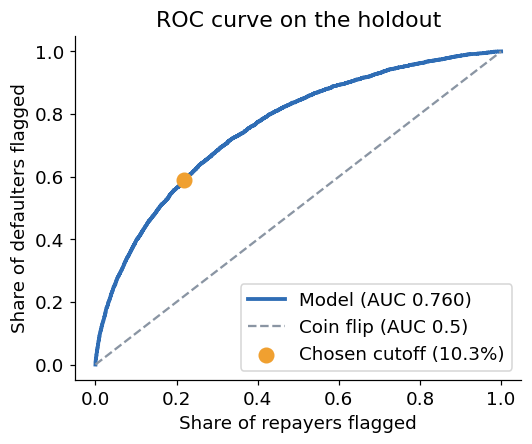

In [4]:
show(pd.DataFrame({"AUC measure": ["3-fold cross-validation (246,008 development rows)", "Holdout (20% of training data, never used for fitting or tuning)",
                                    "Kaggle public leaderboard (part of the test set)", "Kaggle private leaderboard (rest of the test set)", "Benchmarks: majority class / one-variable model"],
                   "AUC": [f"{CV_AUC:.4f} (std. {CV_STD:.4f} across folds)", f"{HOLDOUT_AUC:.4f}", f"{KAGGLE_PUBLIC:.5f}", f"{KAGGLE_PRIVATE:.5f}", "0.5000 / 0.7164"]}))
say(f"""
The holdout figure comes from the same settings fitted on the other 80% of the training data. The Kaggle scores come from the final model scoring the competition's test applications, whose outcomes are not public. The public and private scores agree closely, so the result is stable, but both are about {HOLDOUT_AUC-KAGGLE_PRIVATE:.3f} below the holdout. Possible reasons are that I picked the final settings on the holdout, and that the test applications differ slightly from the training sample. I treat **{KAGGLE_PRIVATE:.3f} as the planning estimate**.

**At the chosen cutoff of {pc(THRESHOLD)}** (applications predicted at or above it are flagged as likely to default), measured on the {n_hold:,}-application holdout:
""")
show(pd.DataFrame({"Metric": ["Precision (flagged applicants who really struggled)", "Recall (struggling applicants who were flagged)", "Share of applicants flagged", "Approval rate",
                              "Default rate among approved", "Default rate among flagged"],
                   "Value": [pc(PREC), pc(REC), pc(flag.mean()), pc(1 - flag.mean()), pc(fn / (fn + tn)), pc(tp / (tp + fp))]}))
show(pd.DataFrame({"": ["Not flagged (approved)", "Flagged (decline or review)"], "Repaid": [f"{tn:,}", f"{fp:,}"], "Payment difficulty": [f"{fn:,}", f"{tp:,}"]}))
say(f"""
Precision looks low ({pc(PREC,0)}) because defaults are rare: even among the flagged group, about 4 in 5 would have repaid. That is acceptable only because the cutoff is based on costs, and flagged applicants are sent to review rather than automatically declined. Recall of {pc(REC,0)} means the cutoff catches roughly three in five of the applicants who go on to have trouble, while flagging {pc(flag.mean(),0)} of all applicants.
""")
from sklearn.metrics import roc_curve
fpr_, tpr_, _ = roc_curve(y_hold, p_hold)
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.plot(fpr_, tpr_, color=BLUE, lw=2.5, label=f"Model (AUC {HOLDOUT_AUC:.3f})")
ax.plot([0, 1], [0, 1], "--", color=GREY, label="Coin flip (AUC 0.5)")
ax.scatter([fp / (fp + tn)], [REC], color=ORANGE, s=90, zorder=5, label=f"Chosen cutoff ({pc(THRESHOLD)})")
ax.set_xlabel("Share of repayers flagged"); ax.set_ylabel("Share of defaulters flagged"); ax.set_title("ROC curve on the holdout"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 4. Decision Threshold Analysis

### 4.1 Cost assumptions and sources

The right cutoff depends on two numbers: how much Home Credit earns when a loan is repaid, and how much it loses when one is not. I anchored both in published figures. Neither is Home Credit's internal data, so both are tested in the sensitivity analysis below. Both are expressed as a share of the loan amount.

| Assumption | Base case | Range tested | Evidence |
|---|---|---|---|
| **Profit on a repaid loan** | 8% of the loan amount | 4% to 12% | Home Credit B.V. reported a net interest margin of 15.8% and a cost-to-income ratio of 42.2% for 2018 [1]. Together these imply roughly 9% a year on the average balance after operating costs (15.8% × (1 − 42.2%)), which is about 5% to 9% of the original amount for loans lasting one to two years, because balances shrink as the loan is repaid. I use 8%, toward the upper end, because the loan terms in this data are unknown. This is my approximation, not a reported figure. |
| **Recovery rate on a defaulted loan** | 30% | 10% to 50% | Fitch assumed a 30% lifetime recovery rate for the unsecured consumer loans in a rated Spanish securitization [2]. A Dutch unsecured consumer-loan portfolio showed recoveries averaging about 35% over 15 years [3]. |
| **Loss given default (LGD = 1 − recovery)** | 70% | 50% to 90% | Follows from the recovery rates above. An industry glossary describes 60% to 90% as typical for unsecured consumer loans [4]. A rating agency assumed that about 15% of defaulted unsecured consumer loans cure before provisioning [5], which is why I test an LGD as low as 50%. |

**Cross-check.** With an 8.07% default rate and a 70% loss, the expected credit loss is about 5.6% of the loan amount over the life of the loans. This is the same order of magnitude as Home Credit's reported cost of risk of 9.4% for 2018 [1], which is a yearly figure on the loan portfolio.

**Caveats.** The dataset does not state its currency, loan terms, or interest rates. `TARGET` marks *payment difficulty*, which is broader than final default, so a 70% loss may overstate the cost of some flagged loans. I apply the loss to the full loan amount (`AMT_CREDIT`) and ignore repayments made before default.

### 4.2 Method

Approving a loan with predicted default probability *p* earns the profit rate *G* with probability (1 − *p*) and loses the loss rate *L* with probability *p*. Approval pays off when (1 − *p*) × *G* > *p* × *L*, that is, when ***p* < G / (G + L)**. This is the optimal cutoff if the model's probabilities are well calibrated. The check below shows that they are. I then confirm the cutoff against the **actual** outcomes and loan amounts of the holdout applications.

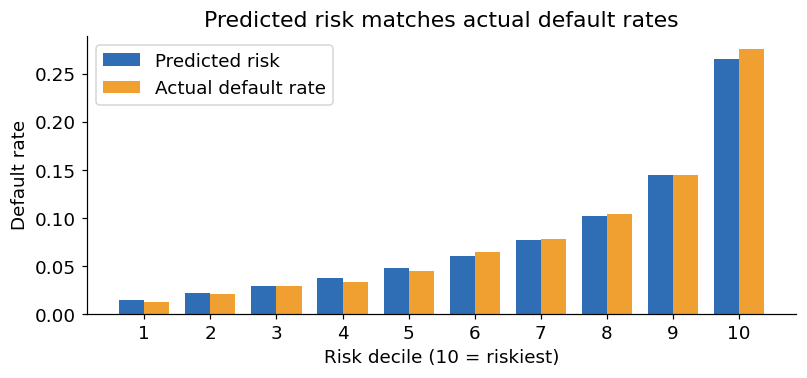


The average predicted risk on the holdout is 8.05% against an actual rate of 8.07%, and the bars track each other across the deciles. That supports using the cost-based cutoff directly.

### 4.3 Chosen threshold

With a profit of 8% and a loss of 70%, the cutoff is 8% ÷ (8% + 70%) = **10.3%**. I use **10.3%**. The empirical check on the holdout, which uses real loan amounts and outcomes, puts the profit-maximizing cutoff at 10.0%, essentially the same.


In [5]:
cal = pd.DataFrame({"p": p_hold, "y": yy})
cal["decile"] = pd.qcut(cal.p.rank(method="first"), 10, labels=range(1, 11)).astype(int)
c = cal.groupby("decile").agg(pred=("p", "mean"), actual=("y", "mean")).reset_index()
fig, ax = plt.subplots(figsize=(7.5, 3.6))
w = 0.38
ax.bar(c.decile - w/2, c.pred, w, color=BLUE, label="Predicted risk"); ax.bar(c.decile + w/2, c.actual, w, color=ORANGE, label="Actual default rate")
ax.set_xticks(c.decile); ax.set_xlabel("Risk decile (10 = riskiest)"); ax.set_ylabel("Default rate"); ax.set_title("Predicted risk matches actual default rates"); ax.legend()
plt.tight_layout(); plt.show()
say(f"""
The average predicted risk on the holdout is {pc(p_hold.mean(),2)} against an actual rate of {pc(yy.mean(),2)}, and the bars track each other across the deciles. That supports using the cost-based cutoff directly.

### 4.3 Chosen threshold

With a profit of {pc(G_BASE,0)} and a loss of {pc(L_BASE,0)}, the cutoff is {pc(G_BASE,0)} ÷ ({pc(G_BASE,0)} + {pc(L_BASE,0)}) = **{pc(T_STAR,1)}**. I use **{pc(THRESHOLD,1)}**. The empirical check on the holdout, which uses real loan amounts and outcomes, puts the profit-maximizing cutoff at {pc(T_EMP,1)}, essentially the same.
""")

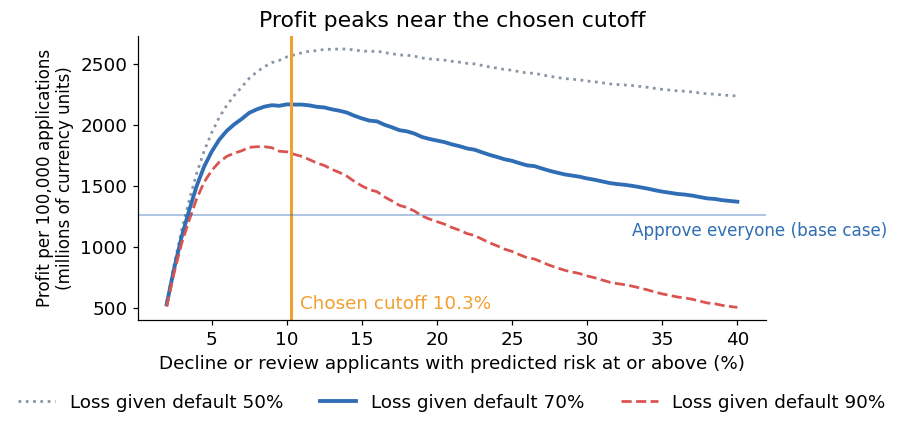

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for L, col, ls in [(0.5, GREY, ":"), (0.7, BLUE, "-"), (0.9, RED, "--")]:
    cv_ = [outcome(p_hold, t, G_BASE, L)["profit_per_100k"] / 1e6 for t in grid]
    ax.plot(grid * 100, cv_, color=col, ls=ls, lw=2.5 if L == 0.7 else 1.8, label=f"Loss given default {L:.0%}")
ax.axvline(THRESHOLD * 100, color=ORANGE, lw=2); ax.text(THRESHOLD * 100 + 0.6, ax.get_ylim()[0] + (ax.get_ylim()[1]-ax.get_ylim()[0]) * 0.04, f"Chosen cutoff {pc(THRESHOLD)}", color=ORANGE, fontsize=12)
ax.axhline(approve_all["profit_per_100k"] / 1e6, color=BLUE, lw=1, alpha=.5); ax.text(33, approve_all["profit_per_100k"] / 1e6 - 60, "Approve everyone (base case)", color=BLUE, fontsize=11, va="top")
ax.set_xlabel("Decline or review applicants with predicted risk at or above (%)"); ax.set_ylabel("Profit per 100,000 applications\n(millions of currency units)", fontsize=11)
ax.set_title("Profit peaks near the chosen cutoff"); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

### 4.4 Sensitivity analysis

**How outcomes change with the cutoff** (base-case costs, holdout applicants). A lower cutoff declines more applicants: it lowers the default rate among approved loans, but gives up profitable lending.

In [7]:
rows = []
for t, label in [(0.05, ""), (0.075, ""), (0.10, ""), (THRESHOLD, " (chosen)"), (0.125, ""), (0.15, ""), (0.20, ""), (0.30, ""), (1.01, "No cutoff (approve all)")]:
    o = outcome(p_hold, t); fl = p_hold >= t
    rows.append({"Cutoff": (f"{t:.1%}" + label) if t < 1 else label, "Approval rate": pc(o["approval_rate"],0), "Default rate, approved": pc(o["approved_default_rate"]),
                 "Precision": pc(precision_score(y_hold, fl)) if fl.any() else "n/a", "Recall": pc(recall_score(y_hold, fl)),
                 "Profit, millions per 100k apps": mil(o["profit_per_100k"]), "Profit, % of loan volume": pc(o["profit_pct_volume"],2)})
show(pd.DataFrame(rows))
say("""
**How the best cutoff and the gain change with the cost assumptions.** Each row is a scenario for profit on a repaid loan (G) and loss given default (L). The optimal cutoff moves from about 4% to 19%, depending on the assumptions. The gain is measured against approving everyone, as a share of loan volume.
""")
sv_tab = pd.DataFrame({"Profit on repaid loan": sens.G.map("{:.0%}".format), "Loss given default": sens.L.map("{:.0%}".format), "Optimal cutoff": sens.t_star.map(lambda v: f"{v:.1%}"),
                       "Gain at the scenario's optimal cutoff": sens.uplift_at_t_emp.map(lambda v: pc(v,2)),
                       f"Gain if the chosen {pc(THRESHOLD)} cutoff is used": sens.uplift_pct_volume.map(lambda v: pc(v,2))})
show(sv_tab)
worst = sens.loc[sens.uplift_pct_volume.idxmin()]
say(f"""
**Reading the sensitivity analysis.** (1) The cutoff matters most when losses are large relative to margins: the more a default costs, the lower the cutoff should be. (2) Even if the base-case cutoff is wrong for the true costs, it still beats approving everyone in {int((sens.uplift_pct_volume > 0).sum())} of 9 scenarios, and the worst case ({pc(worst.G,0)} profit, {pc(worst.L,0)} loss) is {pc(worst.uplift_pct_volume,2)}, effectively break-even. (3) If margins are as low as 4% and losses as high as 90%, lending is close to break-even even at the best cutoff, which is a pricing problem that no score can fix. **Action:** replace the assumed rates with Home Credit's own margin and recovery data and recompute the cutoff before the pilot.

*All profit figures use the 61,503 holdout applications and their actual loan amounts, scaled to 100,000 applications. The data do not state a currency. The baseline "approve everyone" means everyone in the data, who were all granted loans, so the gain over the current underwriting process is probably smaller than shown.*
""")

Cutoff,Approval rate,"Default rate, approved",Precision,Recall,"Profit, millions per 100k apps","Profit, % of loan volume"
5.0%,47%,2.7%,12.9%,84.5%,"1,783",5.98%
7.5%,64%,3.6%,16.0%,71.5%,"2,101",5.24%
10.0%,74%,4.3%,18.9%,60.0%,"2,170",4.71%
10.3% (chosen),75%,4.4%,19.2%,58.8%,"2,171",4.65%
12.5%,81%,4.9%,21.8%,50.5%,"2,145",4.29%
15.0%,86%,5.4%,24.6%,42.2%,"2,055",3.90%
20.0%,92%,6.2%,29.8%,29.0%,"1,873",3.36%
30.0%,97%,7.2%,40.1%,13.1%,"1,563",2.67%
No cutoff (approve all),100%,8.1%,n/a,0.0%,"1,262",2.11%



**How the best cutoff and the gain change with the cost assumptions.** Each row is a scenario for profit on a repaid loan (G) and loss given default (L). The optimal cutoff moves from about 4% to 19%, depending on the assumptions. The gain is measured against approving everyone, as a share of loan volume.


Profit on repaid loan,Loss given default,Optimal cutoff,Gain at the scenario's optimal cutoff,Gain if the chosen 10.3% cutoff is used
4%,50%,7.4%,1.48%,1.39%
4%,70%,5.4%,2.62%,2.23%
4%,90%,4.3%,3.90%,3.07%
8%,50%,13.8%,0.77%,0.68%
8%,70%,10.3%,1.52%,1.52%
8%,90%,8.2%,2.45%,2.36%
12%,50%,19.4%,0.45%,-0.03%
12%,70%,14.6%,0.99%,0.81%
12%,90%,11.8%,1.68%,1.65%



**Reading the sensitivity analysis.** (1) The cutoff matters most when losses are large relative to margins: the more a default costs, the lower the cutoff should be. (2) Even if the base-case cutoff is wrong for the true costs, it still beats approving everyone in 8 of 9 scenarios, and the worst case (12% profit, 50% loss) is -0.03%, effectively break-even. (3) If margins are as low as 4% and losses as high as 90%, lending is close to break-even even at the best cutoff, which is a pricing problem that no score can fix. **Action:** replace the assumed rates with Home Credit's own margin and recovery data and recompute the cutoff before the pilot.

*All profit figures use the 61,503 holdout applications and their actual loan amounts, scaled to 100,000 applications. The data do not state a currency. The baseline "approve everyone" means everyone in the data, who were all granted loans, so the gain over the current underwriting process is probably smaller than shown.*


## 5. Explainability

I explain the final model with SHAP, which splits each prediction into a contribution from every feature (positive values push risk up). The calculation uses a random sample of **1,000 holdout applications**, as planned. Categorical fields are encoded as several columns, so the second chart adds those back together for each original field.

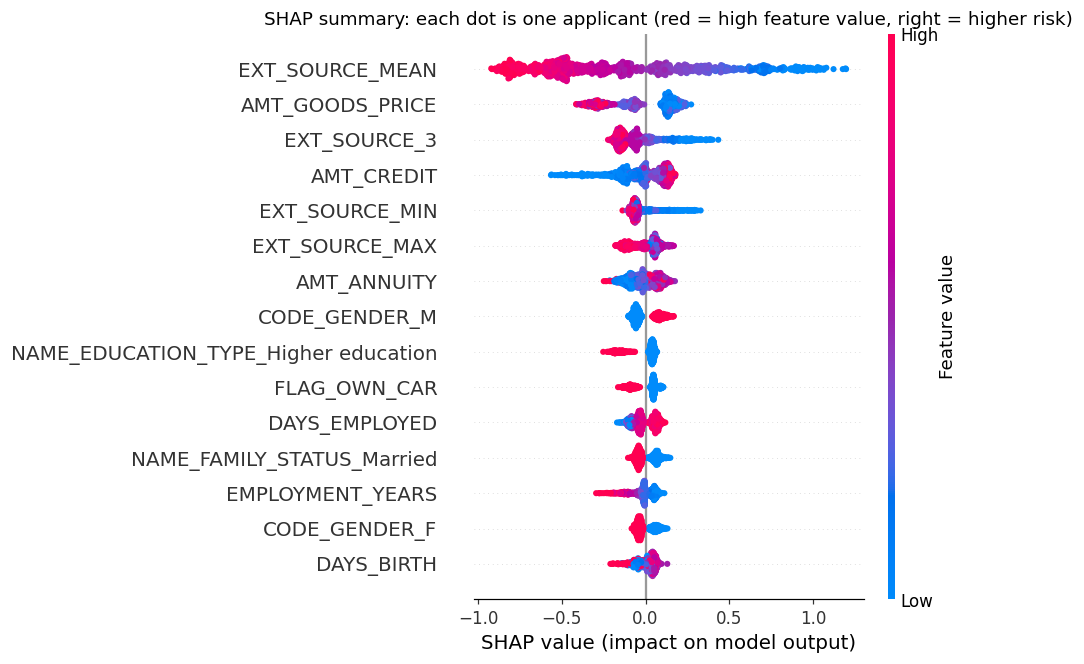

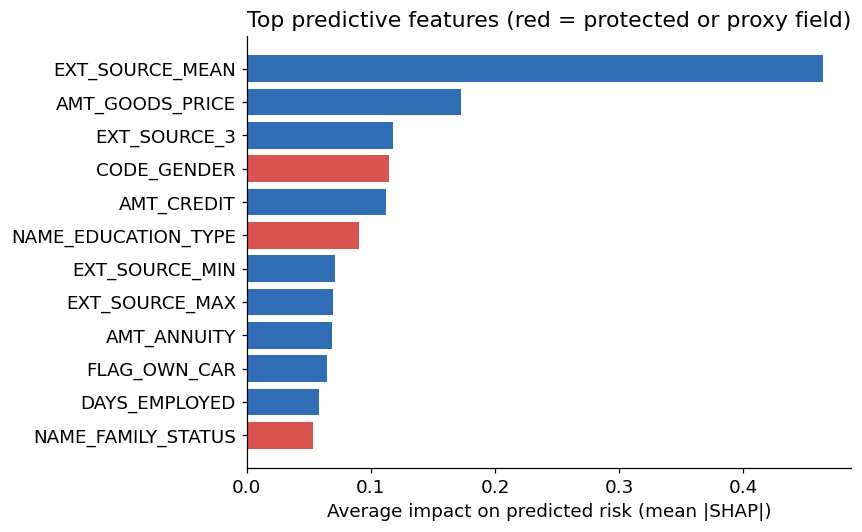


**Top predictive features.**
1. **Outside credit-score data dominates.** `EXT_SOURCE_MEAN` alone has an average impact of 0.46, about 3 times the next field. Together, the mean, minimum, maximum, and individual external scores are the main driver, and low values raise risk. The score's provider and inputs are not documented, so this is the least explainable part of the model.
2. **Loan size and payment.** A larger requested loan (`AMT_CREDIT`), a larger payment (`AMT_ANNUITY`), and a *lower* goods price (`AMT_GOODS_PRICE`) all raise risk. A plausible reading is that a loan that is large relative to the goods being bought is riskier, but I have not tested that.
3. **Employment and assets.** Shorter employment (`EMPLOYMENT_YEARS`, `DAYS_EMPLOYED`) and not owning a car (`FLAG_OWN_CAR`) raise risk.
4. **Protected and proxy fields are among the top drivers.** 3 of the top 12 are such fields: `CODE_GENDER`, `NAME_EDUCATION_TYPE`, `NAME_FAMILY_STATUS`. Gender is the fourth most important feature. These are the fields the EDA marked as high-governance, and section 7 shows their effect.

These are associations, not causes, and SHAP importance describes this model's behavior, not what drives default in the real world.


In [8]:
import shap
fig = plt.figure(figsize=(9, 6.2))
shap.summary_plot(sv, Xt, feature_names=tnames, max_display=15, show=False, plot_size=None)
plt.title("SHAP summary: each dot is one applicant (red = high feature value, right = higher risk)", fontsize=12)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(8, 5))
t12 = imp.head(12).iloc[::-1]
ax.barh(t12.index, t12.values, color=[RED if (f in governed) else BLUE for f in t12.index])
ax.set_xlabel("Average impact on predicted risk (mean |SHAP|)"); ax.set_title("Top predictive features (red = protected or proxy field)")
plt.tight_layout(); plt.show()
gov_top = [f for f in imp.head(12).index if f in governed]
say(f"""
**Top predictive features.**
1. **Outside credit-score data dominates.** `EXT_SOURCE_MEAN` alone has an average impact of {imp['EXT_SOURCE_MEAN']:.2f}, about {imp['EXT_SOURCE_MEAN']/imp.iloc[1]:.0f} times the next field. Together, the mean, minimum, maximum, and individual external scores are the main driver, and low values raise risk. The score's provider and inputs are not documented, so this is the least explainable part of the model.
2. **Loan size and payment.** A larger requested loan (`AMT_CREDIT`), a larger payment (`AMT_ANNUITY`), and a *lower* goods price (`AMT_GOODS_PRICE`) all raise risk. A plausible reading is that a loan that is large relative to the goods being bought is riskier, but I have not tested that.
3. **Employment and assets.** Shorter employment (`EMPLOYMENT_YEARS`, `DAYS_EMPLOYED`) and not owning a car (`FLAG_OWN_CAR`) raise risk.
4. **Protected and proxy fields are among the top drivers.** {len(gov_top)} of the top 12 are such fields: {', '.join('`'+f+'`' for f in gov_top)}. Gender is the fourth most important feature. These are the fields the EDA marked as high-governance, and section 7 shows their effect.

These are associations, not causes, and SHAP importance describes this model's behavior, not what drives default in the real world.
""")

## 6. Adverse Action Mapping

A denied applicant must receive specific, understandable reasons, and complex models are not exempt (see the CFPB references [6][7]). I translate the top features into plain wording, and I use only wording that is appropriate to cite. Each feature gets one of three statuses:

- **Usable:** describes the applicant's own financial situation, and can be put on a notice.
- **Legal review:** might be acceptable, but needs a compliance check before use.
- **Do not cite:** a protected characteristic or a proxy for one. These fields should not be in the model at all, and must never appear as a reason.

In [9]:
show(amap)
say("""
**Notes.** Most of the model's top fields can be explained in plain wording. But three of the top twelve (gender, education, family status) cannot be cited, and they still affect the score, so an honest explanation would have to leave out part of the real reason. That is a strong reason to remove them. The external-score wording is generic. If the score provider supplies its own reason codes, those should replace it.

**Worked examples.** The notice below lists up to four reasons for three applicants in the sample who were above the cutoff, ranked by how much each contributed to the applicant's risk. Only fields with status *Usable* are eligible.
""")
show(examples)

Feature,Mean |SHAP|,What raises risk,Plain-language reason,Status
EXT_SOURCE_MEAN,0.464,low values raise risk,Low score from external credit-data sources,Usable
AMT_GOODS_PRICE,0.173,low values raise risk,Requested loan amount is high compared with the price of the goods financed,Usable
EXT_SOURCE_3,0.118,low values raise risk,Low score from external credit-data sources,Usable
CODE_GENDER,0.115,category,Not citable: protected characteristic or proxy for one,Do not cite
AMT_CREDIT,0.112,high values raise risk,Size of the requested loan amount,Usable
NAME_EDUCATION_TYPE,0.090,category,Not citable: protected characteristic or proxy for one,Do not cite
EXT_SOURCE_MIN,0.071,low values raise risk,Low score from external credit-data sources,Usable
EXT_SOURCE_MAX,0.069,low values raise risk,Low score from external credit-data sources,Usable
AMT_ANNUITY,0.068,high values raise risk,Size of the required regular payment,Usable
FLAG_OWN_CAR,0.065,low values raise risk,Limited assets on record,Legal review



**Notes.** Most of the model's top fields can be explained in plain wording. But three of the top twelve (gender, education, family status) cannot be cited, and they still affect the score, so an honest explanation would have to leave out part of the real reason. That is a strong reason to remove them. The external-score wording is generic. If the score provider supplies its own reason codes, those should replace it.

**Worked examples.** The notice below lists up to four reasons for three applicants in the sample who were above the cutoff, ranked by how much each contributed to the applicant's risk. Only fields with status *Usable* are eligible.


Applicant,Predicted risk,Reasons for denial
A,47.0%,1. Low score from external credit-data sources2. Requested loan amount is high compared with the price of the goods financed3. Size of the required regular payment4. Short length of employment
B,16.7%,1. Low score from external credit-data sources2. Size of the required regular payment3. Limited recent credit-inquiry history4. Size of the requested loan amount
C,10.4%,1. Requested loan amount is high compared with the price of the goods financed2. Short length of employment3. Size of the required regular payment4. Size of the requested loan amount


## 7. Fairness Analysis

I compare approval rates by `CODE_GENDER` and `NAME_EDUCATION_TYPE` at the chosen cutoff on the holdout. Approval rate is the share of applicants *not* flagged. The "approval ratio" divides each group's rate by the highest group's, as a screening heuristic (ratios under 0.80 deserve attention, the "four-fifths" rule of thumb). It is not a legal test. Groups with fewer than 200 applicants are shown but not charted or compared. Rare categories were grouped as "Other" in data preparation.

For contrast, I also show a second model, trained on the same settings but **without the high-governance fields**, at the same cutoff.

**Gender: final model**

Group,Applicants,"Default rate, all applicants",Approval rate,"Default rate, approved",Defaulters flagged,Repayers declined,Approval ratio vs highest
F,"40,561",7.0%,80.2%,4.2%,51.4%,17.4%,1.00
M,"20,940",10.2%,65.7%,4.8%,68.7%,30.4%,0.82
Other,2,0.0%,50.0%,0.0%,n/a,50.0%,0.62


**Gender: model without high-governance fields**

Group,Applicants,"Default rate, all applicants",Approval rate,"Default rate, approved",Defaulters flagged,Repayers declined,Approval ratio vs highest
F,"40,561",7.0%,77.8%,4.1%,54.6%,19.8%,1.00
M,"20,940",10.2%,70.3%,5.4%,62.4%,26.0%,0.90
Other,2,0.0%,50.0%,0.0%,n/a,50.0%,0.64


**Education: final model**

Group,Applicants,"Default rate, all applicants",Approval rate,"Default rate, approved",Defaulters flagged,Repayers declined,Approval ratio vs highest
Higher education,"15,061",5.2%,87.2%,3.5%,41.8%,11.3%,1.00
Incomplete higher,"1,988",7.9%,72.7%,4.2%,61.8%,24.4%,0.83
Lower secondary,791,10.4%,65.9%,6.0%,62.2%,30.9%,0.76
Other,40,2.5%,77.5%,0.0%,100.0%,20.5%,0.89
Secondary / secondary special,"43,623",9.0%,71.5%,4.8%,62.0%,25.2%,0.82


**Education: model without high-governance fields**

Group,Applicants,"Default rate, all applicants",Approval rate,"Default rate, approved",Defaulters flagged,Repayers declined,Approval ratio vs highest
Higher education,"15,061",5.2%,82.2%,3.2%,49.0%,16.0%,1.00
Incomplete higher,"1,988",7.9%,67.8%,3.7%,68.2%,29.2%,0.82
Lower secondary,791,10.4%,68.0%,5.8%,62.2%,28.5%,0.83
Other,40,2.5%,77.5%,0.0%,100.0%,20.5%,0.94
Secondary / secondary special,"43,623",9.0%,73.3%,5.0%,59.2%,23.5%,0.89


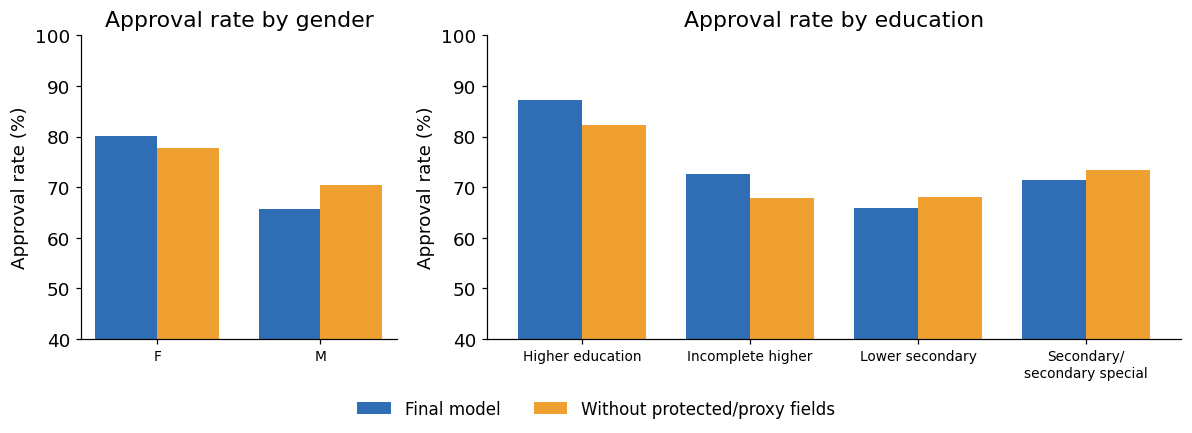


**What the numbers show.**
- **Gender.** The final model approves women at 80% and men at 66% (ratio 0.82). It declines 30% of men who would have repaid, against 17% of women. Men do default more often in this data (10.2% vs. 7.0%), so part of the gap reflects real differences in outcomes. But the model uses gender directly, and the rates among *approved* loans are close (4.2% vs. 4.8%).
- **Education.** Approval ranges from 66% (Lower secondary) to 87% (higher education), a ratio of 0.76, below the 0.80 screening line. Lower education groups also have the highest share of repayers declined.
- **Without the protected and proxy fields**, the gender ratio improves to 0.90 and the lowest education ratio to 0.82, but the gaps do not disappear. The remaining differences come from fields that correlate with gender and education, such as outside credit scores, employment, and loan size. The cost is small: 0.007 AUC and 1.2% of expected profit at the same cutoff.

**Implications.** (1) Using gender as a model input is not acceptable for a lending decision, and removing it is a precondition for any use. (2) Education is not a legally protected characteristic but it is a strong proxy for income and background, and the gaps could still raise disparate-impact questions. (3) Only two attributes were checked. Age, family status, region, and combinations of attributes also need review, along with fair-lending counsel, before a pilot. (4) A single cutoff may not be equally appropriate for all groups, and I did not test alternatives such as group-specific cutoffs or fairness constraints.


In [10]:
g = fair["CODE_GENDER"]
say("**Gender: final model**")
show(fmt_group(g["final"], g["base"]))
say("**Gender: model without high-governance fields**")
show(fmt_group(g["nogov"], g["base"]))
e = fair["NAME_EDUCATION_TYPE"]
say("**Education: final model**")
show(fmt_group(e["final"], e["base"]))
say("**Education: model without high-governance fields**")
show(fmt_group(e["nogov"], e["base"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 2.2]})
for ax, tabs, title in [(axes[0], g, "Gender"), (axes[1], e, "Education")]:
    a, b = tabs["final"], tabs["nogov"]; keep_ = a[a.n >= 200].group.tolist()
    a, b = a.set_index("group").loc[keep_], b.set_index("group").loc[keep_]
    xs = np.arange(len(keep_)); w = 0.38
    ax.bar(xs - w/2, a.approval_rate * 100, w, color=BLUE, label="Final model"); ax.bar(xs + w/2, b.approval_rate * 100, w, color=ORANGE, label="Without protected/proxy fields")
    ax.set_xticks(xs); ax.set_xticklabels([k.replace(" / ", "/\n").replace("Secondary", "Secondary") for k in keep_], fontsize=9); ax.set_ylim(40, 100)
    ax.set_title(f"Approval rate by {title.lower()}"); ax.set_ylabel("Approval rate (%)")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=2, frameon=False, fontsize=11)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()
gr, gname = ratio_min(g["final"]); er, ename = ratio_min(e["final"]); gr2, _ = ratio_min(g["nogov"]); er2, ename2 = ratio_min(e["nogov"])
gf = g["final"].set_index("group")
say(f"""
**What the numbers show.**
- **Gender.** The final model approves women at {pc(gf.approval_rate['F'],0)} and men at {pc(gf.approval_rate['M'],0)} (ratio {gr:.2f}). It declines {pc(gf.false_pos_rate['M'],0)} of men who would have repaid, against {pc(gf.false_pos_rate['F'],0)} of women. Men do default more often in this data ({pc(g['base'].set_index('group').base_rate['M'])} vs. {pc(g['base'].set_index('group').base_rate['F'])}), so part of the gap reflects real differences in outcomes. But the model uses gender directly, and the rates among *approved* loans are close ({pc(gf.default_rate_approved['F'])} vs. {pc(gf.default_rate_approved['M'])}).
- **Education.** Approval ranges from {pc(e['final'][e['final'].n>=200].approval_rate.min(),0)} ({ename}) to {pc(e['final'][e['final'].n>=200].approval_rate.max(),0)} (higher education), a ratio of {er:.2f}, below the 0.80 screening line. Lower education groups also have the highest share of repayers declined.
- **Without the protected and proxy fields**, the gender ratio improves to {gr2:.2f} and the lowest education ratio to {er2:.2f}, but the gaps do not disappear. The remaining differences come from fields that correlate with gender and education, such as outside credit scores, employment, and loan size. The cost is small: {HOLDOUT_AUC-NOGOV_AUC:.3f} AUC and {pc((at_t['profit']-nogov_at_t['profit'])/at_t['profit'])} of expected profit at the same cutoff.

**Implications.** (1) Using gender as a model input is not acceptable for a lending decision, and removing it is a precondition for any use. (2) Education is not a legally protected characteristic but it is a strong proxy for income and background, and the gaps could still raise disparate-impact questions. (3) Only two attributes were checked. Age, family status, region, and combinations of attributes also need review, along with fair-lending counsel, before a pilot. (4) A single cutoff may not be equally appropriate for all groups, and I did not test alternatives such as group-specific cutoffs or fairness constraints.
""")

## 8. Limitations and Risks

**Known limitations**
- **Moderate predictive power.** AUC is about 0.75 on independent Kaggle data. At the chosen cutoff, only about 1 in 5 flagged applicants actually has payment difficulty, so most flagged applicants are good customers. A decline with no review would turn away many of them.
- **Selection bias.** The training data contain only applications that became loans. The model has never seen declined applicants, so it may behave poorly for applicants unlike those Home Credit approved, and it cannot show the effect of approving more.
- **Outcome definition.** `TARGET` is payment difficulty, not necessarily 90+ day delinquency or loss. Business metrics such as expected credit loss need an outcome and loss definition that match.
- **Assumed costs.** Profit and loss rates come from published sources for other portfolios, not Home Credit's own data. The cutoff should be recomputed with internal figures.
- **Protected and proxy fields.** The model uses gender, education, family status, and age-related fields (section 7), which must be removed before use.
- **Unexplained inputs.** The three outside scores carry most of the model, but their provider, inputs, and timing are unknown, so they cannot be audited, and they could become unavailable or change.

**Where it might fail**
- **Thin-file applicants.** They were not evaluated separately. Missing outside scores are common (the first score is missing for 56% of applicants), and the model's accuracy for this group is unknown. This is the group the business most wants to serve.
- **Changing conditions.** The training period is unknown, and the model will degrade if the economy, products, or applicant mix change. The Kaggle drop from the holdout suggests some difference already.
- **Small groups.** Estimates for rare education levels and genders rest on very few applicants.
- **Probability scale.** The probabilities are well calibrated on this data, but should be rechecked on current data before they feed loss estimates.

**Missing data.** Bureau records, previous Home Credit loans, and payment histories (available in the supplementary tables) are not used. Other missing information includes verified income, loan term and interest rate, loss amounts, current-process decisions, and the dates of applications.

**Recommended safeguards.** Remove protected and proxy fields. Run a shadow period and a pilot before any live decisions. Keep human review for flagged applicants. Monitor ranking quality, calibration, input drift, and approval and default rates by group on a regular schedule. Document the retraining and rollback process.

## 9. References

1. Home Credit B.V., *IFRS consolidated results for the full year ended 31 December 2018 and Q1 2019* (press release, 28 June 2019). Net interest margin 15.8%, cost-to-income ratio 42.2%, cost of risk 9.4%. https://www.homecredit.net/wp-content/uploads/2022/11/190628-HCBV-FY18_Q1_2019-Results-Announcement.pdf
2. Fitch Ratings, new issue report for CaixaBank Consumo 2, FT (recovery-rate expectation of 30% for unsecured consumer loans). https://www.caixabank.cat/deployedfiles/gesticaixa/Estaticos/PDF/GestiCaixa/FITCH_Consumo_2_FT_NIR_published.pdf
3. TwentyFour Asset Management (Vontobel), *Asset-backed finance case study: Qander Consumer Finance* (Dutch unsecured consumer loans; recoveries averaging about 35%). https://am.vontobel.com/en/insights/asset-backed-finance-abf-case-study-qander-consumer-finance
4. Vergent LMS, *Loss Given Default (LGD)* glossary entry (60% to 90% typical for unsecured consumer loans; an industry source, used only as a range check). https://www.vergentlms.com/?p=8609
5. Scope Ratings, rating report for a Spanish consumer-loan securitization (assumed 15% cure rate for unsecured consumer loans). https://scoperatings.com/ratings-and-research/rating/EN/159325
6. Consumer Financial Protection Bureau, *Credit discrimination is illegal* (as referenced in the project's feature report). https://www.consumerfinance.gov/consumer-tools/credit-reports-and-scores/credit-discrimination-is-illegal/
7. Consumer Financial Protection Bureau, *Circular 2022-03: Adverse action notification requirements in connection with credit decisions based on complex algorithms* (as referenced in the project's feature report). https://www.consumerfinance.gov/compliance/circulars/circular-2022-03-adverse-action-notification-requirements-in-connection-with-credit-decisions-based-on-complex-algorithms/
8. Kaggle, *Home Credit Default Risk* competition (data and AUC evaluation).
9. Project files: `EDA_Home_Credit.ipynb`, `Data_Prep.py`, `Modeling_Home_Credit.ipynb`.